# Predicting Face Counts


## Imports


In [ ]:
import cv2
import os
import random
import numpy as np
import pandas as pd
import IPython.display as display

from typing import Literal
from pathlib import Path
from PIL import Image
from cv2.typing import MatLike

# model training
from tqdm import tqdm
from xgboost import XGBRegressor
from skimage.feature import hog, local_binary_pattern
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# dimensionality reduction
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

In [3]:
DATA_DIR = Path("data")
TRAIN_IMG_DIR = DATA_DIR / "train"
TEST_IMG_DIR = DATA_DIR / "test"

In [4]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

In [5]:
print(train_df.columns)
print(train_df['type'].value_counts())

Index(['image_id', 'type', 'count'], dtype='str')
type
faces    2861
coins     723
Name: count, dtype: int64


In [6]:
# filter to leave only the "face" type
train_df = train_df[train_df['type'] == 'faces']
print(train_df['count'].unique())
print(len(train_df))

[ 4  2  3  5  8  6  1 10  7 11 14 12  9 13 15 19 16 17 28 23 18 29 24]
2861


In [7]:
img = cv2.imread(str(TRAIN_IMG_DIR / train_df.iloc[0]['image_id']) + ".jpg")

if img is None:
    raise ValueError("Could not read image")

print(img.shape)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print(gray.shape)
print(type(gray))

(408, 612, 3)
(408, 612)
<class 'numpy.ndarray'>


In [8]:
def render_cv_image(image: MatLike | None) -> None:
    if image is None:
        raise ValueError("Image is None")
    # Convert BGR to RGB (OpenCV uses BGR by default)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    # Convert to PIL Image
    pil_image = Image.fromarray(image_rgb)
    # Display the image in the notebook
    display.display(pil_image)

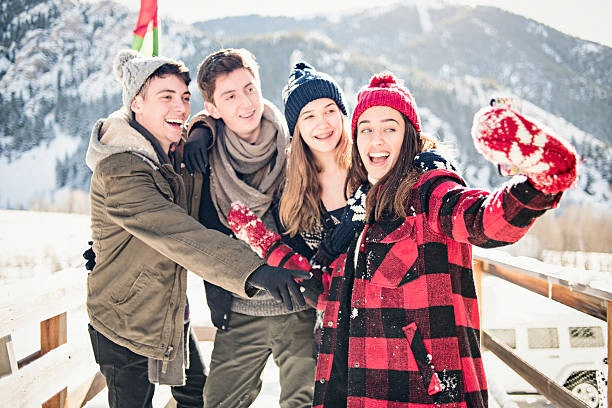

In [9]:
render_cv_image(img)

## Model


## Data Split

In [10]:
print(train_df['count'].value_counts())

count
3     710
4     618
2     530
5     404
6     229
7     134
8      74
9      41
1      30
10     26
11     18
12     15
13     11
14      8
15      2
19      2
16      2
18      2
17      1
28      1
23      1
29      1
24      1
Name: count, dtype: int64


In [11]:
# Create stratification groups - combine rare classes into a single group
def get_stratify_groups(counts):
    """Group rare classes together for stratification"""
    value_counts = counts.value_counts()
    rare_classes = value_counts[value_counts < 2].index
    
    # Map rare classes to a special 'rare' group (-1)
    stratify_groups = counts.copy()
    stratify_groups[counts.isin(rare_classes)] = -1
    
    return stratify_groups

In [ ]:
stratify_groups = get_stratify_groups(train_df['count'])

print(f"Rare classes (count=1): {train_df['count'].value_counts()[train_df['count'].value_counts() == 1].index.tolist()}")
print(f"Stratification groups: {stratify_groups.value_counts().sort_index()}")

# Split with modified stratification
X_train, X_val, y_train, y_val = train_test_split(
    train_df[['image_id', 'count']],
    train_df['count'],
    test_size=0.2,
    stratify=stratify_groups,
    random_state=SEED
)

print(f"\nTrain set size: {len(X_train)}")
print(f"Validation set size: {len(X_val)}")

Rare classes (count=1): [17, 28, 23, 29, 24]
Stratification groups: count
-1       5
 1      30
 2     530
 3     710
 4     618
 5     404
 6     229
 7     134
 8      74
 9      41
 10     26
 11     18
 12     15
 13     11
 14      8
 15      2
 16      2
 18      2
 19      2
Name: count, dtype: int64

Train set size: 2288
Validation set size: 573


In [13]:
print(X_train['count'].value_counts())

count
3     568
4     494
2     424
5     323
6     183
7     107
8      59
9      33
1      24
10     21
11     14
12     12
13      9
14      6
16      2
19      2
15      2
29      1
18      1
24      1
17      1
28      1
Name: count, dtype: int64


### Feature Extraction

In [ ]:
def extract_features(image_path: Path) -> np.ndarray:
    """Extract HOG and LBP features from image"""
    # Read image
    img = cv2.imread(str(image_path))
    if img is None:
        return np.zeros(0)

    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Resize to standard size for consistent feature dimensions
    gray = cv2.resize(gray, (256, 256))

    # Extract HOG features
    hog_features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        visualize=False,
        feature_vector=True
    )

    # Extract LBP features
    radius = 3
    n_points = 8 * radius
    lbp = local_binary_pattern(gray, n_points, radius, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=n_points + 2, range=(0, n_points + 2))
    lbp_hist = lbp_hist.astype('float32')
    lbp_hist /= (lbp_hist.sum() + 1e-7)  # Normalize

    # Combine features
    features = np.concatenate([hog_features, lbp_hist])

    return features

In [15]:
# Extract features for all training images
print("Extracting features from training set...")
X_train_features = []
y_train_counts = []

for idx, row in tqdm(X_train.iterrows(), total=len(X_train), desc="Extracting features"):
    img_path = TRAIN_IMG_DIR / f"{row['image_id']}.jpg"
    features = extract_features(img_path)
    if features.size > 0:
        X_train_features.append(features)
        y_train_counts.append(row['count'])

Extracting features from training set...


Extracting features: 100%|██████████| 2288/2288 [02:08<00:00, 17.85it/s]


In [16]:
X_train_features = np.array(X_train_features)
y_train_counts = np.array(y_train_counts)

print(f"Feature matrix shape: {X_train_features.shape}")
print(f"Target shape: {y_train_counts.shape}")

Feature matrix shape: (2288, 34622)
Target shape: (2288,)


### Dimensionality Reduction

In [ ]:
def get_fitted_reducer(X, method: Literal["pca", "tsne", "umap", "svd"], **kwargs) -> PCA | TSNE | TruncatedSVD:
    var_explained = kwargs.get("var_explained", 0.95)
    n_components = kwargs.get("n_components", 2550)
    perplexity = kwargs.get("perplexity", 30)
    eps = kwargs.get("eps", 0.5)
    min_samples = kwargs.get("min_samples", 5)

    if method == "pca":
        reducer = PCA(n_components=var_explained, random_state=SEED)
        reducer.fit(X)
        print(f"PCA will reduce to {reducer.n_components_}")
        print(f"PCA explained variance: {reducer.explained_variance_ratio_.sum():.2f}")
    elif method == "tsne":
        print(n_components, perplexity)
        reducer = TSNE(n_components=n_components, random_state=SEED, perplexity=perplexity)
        reducer.fit(X)
        print(f"t-SNE will reduce to {n_components} components with perplexity {perplexity}")
    elif method == "umap":
        reducer = ...
        raise NotImplementedError("UMAP is not implemented in this environment")
    elif method == "svd":
        reducer = TruncatedSVD(n_components=n_components, random_state=SEED)
        reducer.fit(X)
        print(f"SVD will reduce to {n_components} components")
    else:
        raise ValueError("Invalid dimensionality reduction type")
    
    return reducer

In [64]:
def reduce_dimensionality(X: np.ndarray, reducer: PCA | TSNE | TruncatedSVD) -> np.ndarray:
    if isinstance(reducer, (PCA, TruncatedSVD)):
        return reducer.transform(X)
    else:
        # t-SNE doesn't support transform(), should not be used for prediction
        raise ValueError("t-SNE cannot be used for new data prediction. Use PCA or SVD instead.")

In [49]:
# Add after scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_features)

# Apply dimensionality reduction
pca_kwargs = {"var_explained": 0.95}
tsne_kwargs = {"n_components": 2000, "perplexity": 30}
svd_kwargs = {"n_components": 2000}
reducer = get_fitted_reducer(X_train_scaled, method="svd", **svd_kwargs)

SVD will reduce to 2000 components


In [62]:
X_train_reduced = reduce_dimensionality(X_train_scaled, reducer)

print(f"Reduced from {X_train_scaled.shape[1]} to {X_train_reduced.shape[1]} features")
print(X_train_reduced.shape)

Reduced from 34622 to 2000 features
(2288, 2000)


## Model Training

In [52]:
# Model 1: Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
rf_model.fit(X_train_reduced, y_train_counts)
print("Random Forest trained successfully!")

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    7.5s
[Parallel(n_jobs=-1)]: Done 160 tasks      | elapsed:  1.2min


Random Forest trained successfully!


[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  1.5min finished


In [ ]:
# Model 2: XGBoost
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=1
)
xgb_model.fit(X_train_reduced, y_train_counts)
print("XGBoost trained successfully!")

XGBoost trained successfully!


In [54]:
# Model 3: Gradient Boosting
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    random_state=42,
    verbose=1
)
gb_model.fit(X_train_reduced, y_train_counts)
print("Gradient Boosting trained successfully!\n")

print("Models trained successfully!")

      Iter       Train Loss      OOB Improve   Remaining Time 
         1           5.3793          -0.0170            5.44m
         2           5.1469          -0.3492            5.46m
         3           5.3381           1.3432            5.41m
         4           4.9119          -1.1118            5.40m
         5           4.9490           0.7350            5.36m
         6           4.7257          -0.4627            5.32m
         7           4.6131          -0.0762            5.30m
         8           4.8315           1.1846            5.28m
         9           4.3693          -1.4722            5.26m
        10           4.5719           1.1955            5.22m
        20           3.6025          -0.7407            4.90m
        30           3.0111           0.1145            4.55m
        40           2.3024          -0.2690            4.23m
        50           1.8726           0.1849            3.93m
        60           1.3745           0.0283            3.64m
       

In [76]:
def count_faces(image_path: Path, single_model: RandomForestRegressor | XGBRegressor | GradientBoostingRegressor, is_ensemble: bool = False) -> int:
    features = extract_features(image_path)
    if features.size == 0:
        return 0

    # Scale features
    features_scaled = scaler.transform(features.reshape(1, -1))
    features_reduced = reduce_dimensionality(features_scaled, reducer)

    if is_ensemble:
        # Get predictions from all models
        rf_pred = rf_model.predict(features_reduced)[0]
        xgb_pred = xgb_model.predict(features_reduced)[0]
        gb_pred = gb_model.predict(features_reduced)[0]

        # Average predictions
        prediction = (rf_pred + gb_pred) / 2
    else:
        # Predict with the single model passed in
        prediction = single_model.predict(features_reduced)[0]

    # Since we know there's at least 1 face, clip to minimum of 1
    prediction = max(1, round(prediction))

    return int(prediction)

## Evaluating


In [77]:
X_val["predicted_count"] = X_val["image_id"].apply(lambda img_id: count_faces(TRAIN_IMG_DIR / f"{img_id}.jpg", single_model=gb_model, is_ensemble=True))

[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 160 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 160 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 160 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Do

In [78]:
# calculate MCRMSE: Mean Columnwise Root Mean Square Error
X_val["squared_error"] = np.square(X_val["predicted_count"] - X_val["count"])
mcrmse = np.sqrt(X_val["squared_error"].mean())
print(f"MCRMSE: {mcrmse}")

MCRMSE: 2.297657962293963


In [ ]:
X_val[["predicted_count", "count", "squared_error"]].head()

,predicted_count,count,squared_error
320,3,5,4
231,4,5,1
3299,2,2,0
3551,5,5,0
1028,4,3,1


Table of results:

| Feature Extraction | Reduction | Regression | MCRMSE |
| ------------------ | --------- | ---------- | ------ |
| DoG + LBP          | PCA       | XGBoost    | 2.36   |
| DoG + LBP          | PCA       | RF         | 2.30   |
| DoG + LBP          | PCA       | GB         | 2.32   |
| DoG + LBP          | PCA       | Ensemble   | 2.31   |
| DoG + LBP          | SVD       | XGBoost    | 2.34   |
| DoG + LBP          | SVD       | RF         | 2.29   |
| DoG + LBP          | SVD       | GB         | 2.29   |
| DoG + LBP          | SVD       | Ensemble   | 2.29   |

## Train on whole training set and predict on test set

In [79]:
# Extract features for all training images
print("Extracting features from training set...")
X_train_features = []
y_train_counts = []

for idx, row in tqdm(train_df.iterrows(), total=len(train_df), desc="Extracting features"):
    img_path = TRAIN_IMG_DIR / f"{row['image_id']}.jpg"
    features = extract_features(img_path)
    if features.size > 0:
        X_train_features.append(features)
        y_train_counts.append(row['count'])

Extracting features from training set...


Extracting features: 100%|██████████| 2861/2861 [02:04<00:00, 23.05it/s]


In [80]:
X_train_features = np.array(X_train_features)
y_train_counts = np.array(y_train_counts)

print(f"Feature matrix shape: {X_train_features.shape}")
print(f"Target shape: {y_train_counts.shape}")

Feature matrix shape: (2861, 34622)
Target shape: (2861,)


In [81]:
# Add after scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_features)

# Apply dimensionality reduction
pca_kwargs = {"var_explained": 0.95}
tsne_kwargs = {"n_components": 2000, "perplexity": 30}
svd_kwargs = {"n_components": 2000}
reducer = get_fitted_reducer(X_train_scaled, method="svd", **svd_kwargs)

SVD will reduce to 2000 components


In [82]:
X_train_reduced = reduce_dimensionality(X_train_scaled, reducer)

print(f"Reduced from {X_train_scaled.shape[1]} to {X_train_reduced.shape[1]} features")
print(X_train_reduced.shape)

Reduced from 34622 to 2000 features
(2861, 2000)


In [ ]:
# Model 1: Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1,
    verbose=0
)
rf_model.fit(X_train_reduced, y_train_counts)
print("Random Forest trained successfully!")

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   10.9s
[Parallel(n_jobs=-1)]: Done 160 tasks      | elapsed:  1.5min


Random Forest trained successfully!


[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  1.8min finished


In [84]:
# Model 2: XGBoost
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=1
)
xgb_model.fit(X_train_reduced, y_train_counts)
print("XGBoost trained successfully!")

XGBoost trained successfully!


In [85]:
# Model 3: Gradient Boosting
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    random_state=42,
    verbose=1
)
gb_model.fit(X_train_reduced, y_train_counts)
print("Gradient Boosting trained successfully!\n")

print("Models trained successfully!")

      Iter       Train Loss      OOB Improve   Remaining Time 
         1           5.4573          -0.0491            7.41m
         2           4.9680          -1.4915            7.26m
         3           5.1811           1.3534            7.18m
         4           4.6514          -1.6219            7.09m
         5           4.9017           1.4262            7.05m
         6           4.9466           0.7823            6.96m
         7           4.5799          -1.1182            6.94m
         8           4.7669           1.1051            6.90m
         9           4.5687          -0.3985            6.85m
        10           4.4162          -0.1292            6.80m
        20           3.8827          -0.5092            6.40m
        30           3.1472          -0.3168            5.99m
        40           2.6648           0.0470            5.55m
        50           2.1967           0.0929            5.16m
        60           1.7546          -0.0178            4.80m
       

In [88]:
test_df["predicted_count"] = test_df["image_id"].apply(
    lambda img_id: count_faces(
        TEST_IMG_DIR / f"{img_id}.jpg",
        single_model=gb_model, is_ensemble=True
    )
)

[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 160 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 160 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 160 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Do

In [90]:
test_df_submission = test_df.copy()

In [93]:
# since model do not know coins, just predict 1 for all type = coins
test_df_submission.loc[test_df_submission['type'] == 'coins', 'predicted_count'] = 4

In [94]:
test_df_submission

,image_id,type,predicted_count
0,b6e281181c11269eaa1c11256c1582c5effec630,faces,4
1,53189001e2ede913f9c1be729d7cabe0036746d3,coins,4
2,aa8b264fd88180788a8dae046ead5bd6198005e6,faces,3
3,705d7c1e06127ddb5d2905cc6806f0c544bc3387,faces,4
4,459864ffbec10f5f863d52909a3e295b8c644a14,faces,4
...,...,...,...
3580,3dab93d9890399d670e88009c23231c578aa2c8b,faces,4
3581,2e092fe3fe9637d5adecebb176376a90d69eb625,faces,4
3582,9143705c46dce87d18de90a5b4246544c639e199,coins,4
3583,b948a478b0aae5df481aa228db7f5fa47f86197c,faces,3


## Submission to Kaggle

In [99]:
submission_df = test_df_submission.rename(columns={"predicted_count": "count"})
submission_df[["image_id", "count"]].to_csv("submission.csv", index=False)

In [98]:
!kaggle competitions submit -c count-coins-and-faces -f submission.csv -m "NO COINS submission with ensemble model and feature engineering"

Successfully submitted to Count Coins And Faces



  0%|          | 0.00/154k [00:00<?, ?B/s]
 10%|█         | 16.0k/154k [00:00<00:03, 46.5kB/s]
100%|██████████| 154k/154k [00:00<00:00, 164kB/s]  


Kaggle public leaderboard score:

$$
\text{MCRMSE} = 4.2
$$

## Attmpt to use Haar pretrained model for face detection

In [100]:
face_cascade = cv2.CascadeClassifier("haarcascade_frontalface_default.xml")

In [101]:
def detect_faces(image_path: Path) -> int:
    img = cv2.imread(str(image_path))
    if img is None:
        return 0

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)

    return max(1, len(faces))

In [102]:
test_df["predicted_count"] = test_df["image_id"].apply(lambda img_id: detect_faces(TEST_IMG_DIR / f"{img_id}.jpg"))

In [110]:
test_df_submission = test_df.rename(columns={"predicted_count": "count"}).copy()

In [111]:
# since model do not know coins, just predict 1 for all type = coins
test_df_submission.loc[test_df_submission['type'] == 'coins', 'count'] = 4

In [113]:
submission_df = test_df_submission.rename(columns={"predicted_count": "count"})
submission_df[["image_id", "count"]].to_csv("submission_haar.csv", index=False)

In [115]:
!kaggle competitions submit -c count-coins-and-faces -f submission_haar.csv -m "NO COINS submission HAAR pretrained model for face detection"

Successfully submitted to Count Coins And Faces



  0%|          | 0.00/154k [00:00<?, ?B/s]
 10%|█         | 16.0k/154k [00:00<00:02, 51.2kB/s]
100%|██████████| 154k/154k [00:01<00:00, 147kB/s]  
